# Support Vector Machine

### Author
   * Jonathan Sancho Loaiza

### Running this notebook

It runs unchanged in Google Colab and on a local Jupyter installation. Every
library it uses, pandas, numpy, scikit-learn, seaborn, matplotlib and joblib, is
already installed in Colab, so there is nothing to `pip install`.

The only thing the notebook needs is the file `fetal_health.csv`, the fetal health
classification dataset from Kaggle. The loading cell reads it from the notebook's
own folder and, if it is not there, from Colab's `sample_data` folder, so upload
the CSV to either of those two places before running.

Run the cells in order, with `Runtime > Run all`. On a Colab CPU the whole
notebook takes a few minutes; the three grid searches in the modelling section
and the cross validated probabilities in the evaluation section are the slow
parts.

## Problem Analysis (CRISP-DM 1: Business Understanding)

A cardiotocograph is the belt strapped around a pregnant woman's abdomen in the
last weeks of pregnancy and during labour. It records two lines at once, the
heart rate of the fetus and the contractions of the uterus, and an obstetrician
reads the two together to decide whether the fetus is coping. The reading is not
a measurement of one number, it is a judgement about the shape of a trace: how
fast the baseline runs, whether the rate accelerates when the fetus moves,
whether it dips after a contraction and how long it takes to come back.

That judgement is the problem. Reading a trace well takes years, agreement
between two experienced readers is far from perfect, and the traces arrive at
three in the morning in a ward where the person on duty is also doing four other
things. Meanwhile the consequence of reading one wrong is not symmetric at all: a
fetus in distress that is read as healthy can end in permanent injury or death,
while a healthy fetus read as distressed ends in an extra hour of monitoring or,
at worst, a caesarean that was not needed.

The dataset holds 2126 cardiotocograph traces, collected in Porto, Portugal, that
three expert obstetricians read and agreed on, reduced to 21 numbers each. Some
of those numbers are counts of events per second, such as accelerations and
decelerations of the heart rate. Some describe the variability of the trace,
which is the single most informative thing about a fetus, since a healthy nervous
system produces a heart rate that is constantly adjusting and a fetus in trouble
produces a flat one. The rest summarise the histogram of the heart rate over the
recording. The label is the consensus of the three experts on a three point
scale: **Normal**, **Suspect** and **Pathological**.

The task is therefore to reproduce a specialist's reading from those 21 numbers,
and the model chosen for it is a **Support Vector Machine**. The reason is the
shape of the problem rather than a preference. The three classes are not
separated by a straight cut through any single variable, since a low variability
means one thing when accelerations are present and another when they are not, so
the boundary between healthy and distressed is a curved surface in 21 dimensions.
An SVM with a radial basis kernel is built for exactly that: it draws a non
linear boundary while still choosing, among all the boundaries that separate the
data, the one that leaves the widest possible corridor between the classes. On a
dataset of two thousand records and twenty one columns, that margin is what keeps
the model from memorising the training set.

Two things follow from the problem and are decided before any code runs.

The classes are unequal, roughly 78 percent normal against 8 percent
pathological, so a model that answered normal to every trace would be right 78
percent of the time and would be useless. Accuracy is not the criterion here.

And the two errors are not worth the same. A pathological trace called normal is
the failure the whole system exists to prevent; a normal trace called suspect
costs an extra check. The evaluation section is built around that asymmetry, and
the notebook ends by turning the model into a decision that can be tuned towards
the error that is cheaper to make.

### Libraries

In [1]:
# Dataset handling
import os
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Split and validation
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_val_predict,
                                     GridSearchCV)

# Evaluation
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score, recall_score,
                             precision_score,
                             roc_curve, roc_auc_score)

# Saving the model
import joblib

# Same split and same folds on every run
RANDOM_STATE = 1

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
sns.set_style('whitegrid')

## Data Understanding (CRISP-DM 2)

The file `fetal_health.csv` holds the cardiotocography dataset of Ayres de Campos
and colleagues at the University of Porto, distributed through the UCI
repository. Each row is one cardiotocograph recording, each of
the first 21 columns a feature extracted automatically from that recording by the
SisPorto software, and the last column the classification agreed by three expert
obstetricians.

In [2]:
# Load the data. The file is read from the notebook's own folder, and if it is
# not there the Colab sample_data folder is tried, so the notebook runs in both
FILE = 'fetal_health.csv'
path = FILE if os.path.exists(FILE) else '/content/sample_data/' + FILE
fetal = pd.read_csv(path)

# First records
fetal.head()


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,mean_value_of_long_term_variability,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,10.4,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,13.4,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,23.0,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


Every column is numeric, so there is no text to encode, but the columns are not
of one kind and the difference matters later.

Six of them are rates per second: `accelerations`, `fetal_movement`,
`uterine_contractions`, `light_decelerations`, `severe_decelerations` and
`prolongued_decelerations` count how often an event occurred divided by the
length of the recording, so they are small decimals, and the first rows show
values like 0.000, 0.003 and 0.006.

Four describe the variability of the heart rate, which is the clinical core of
the reading: `abnormal_short_term_variability` is the percentage of the recording
whose beat to beat variation was outside the normal band,
`mean_value_of_short_term_variability` its average size,
`percentage_of_time_with_abnormal_long_term_variability` the same idea over
longer windows and `mean_value_of_long_term_variability` its average.

`baseline value` is the baseline heart rate of the trace, and the remaining ten
summarise the histogram of the heart rate over the whole recording: its width,
minimum, maximum, mode, mean, median, variance, the number of peaks and of zeroes
and a tendency flag. Those eleven are the columns written in the largest numbers,
since a fetal heart rate runs around 130 beats per minute.

`fetal_health` is the target, coded 1 for normal, 2 for suspect and 3 for
pathological. It is stored as a float, which is only a detail of how the file was
written, and it is a name and not a quantity: a pathological trace is not three
times a normal one.

In [3]:
# Number of records
print("Record count:", len(fetal))
# Number of columns
print("Column count:", len(fetal.columns))
# Rows and columns
print("Rows and columns:", fetal.shape)
# Dataset information
fetal.info()

Record count: 2126
Column count: 22
Rows and columns: (2126, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         21

The dataset has 2126 records and 22 columns, so 21 predictors and the response,
and `info()` reports 2126 non null values in every one of them with `float64` for
all of them.

Two thousand records with twenty one columns is a comfortable size for a Support
Vector Machine. The cost of fitting an SVM grows faster than the number of
records, roughly between its square and its cube, so a dataset of this size fits
in a second and a grid over a hundred configurations is a matter of minutes,
while the same grid on a hundred thousand records would not be practical. It is
also enough data for a 75 / 25 split to leave a test set of several hundred rows,
which is what makes the evaluation section readable.

In [4]:
# Check for empty values
print("Columns with an empty cell:", fetal.isnull().any().sum(),
      ' / ', len(fetal.columns))
print("Empty cells in total:", fetal.isnull().sum().sum())

Columns with an empty cell: 0  /  22
Empty cells in total: 0


There is no empty cell in the file. This is not a questionnaire, it is the output
of a program that processed a recording, and every one of the 21 features is
computed from the trace whether or not the event it counts occurred. When a
recording contains no prolonged deceleration the column holds 0.0, which is a
measurement and not a gap, and the exploration comes back to those zeros because
their frequency is one of the strongest signals in the dataset.

In [5]:
# Check for duplicated records
print("Duplicated rows:", fetal.duplicated().sum())

# What the repeated records look like, sorted so the copies sit together
duplicates = fetal[fetal.duplicated(keep=False)]
print("Records involved:", len(duplicates))
duplicates.sort_values(list(fetal.columns)).head(6)

Duplicated rows: 13
Records involved: 24


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,mean_value_of_long_term_variability,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
1112,122.0,0.0,0.0,0.0,0.0,0.0,0.0,19.0,1.9,0.0,15.1,39.0,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
1113,122.0,0.0,0.0,0.0,0.0,0.0,0.0,19.0,1.9,0.0,15.1,39.0,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
1114,122.0,0.0,0.0,0.0,0.0,0.0,0.0,19.0,1.9,0.0,15.1,39.0,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
1115,122.0,0.0,0.0,0.0,0.0,0.0,0.0,19.0,1.9,0.0,15.1,39.0,103.0,142.0,1.0,0.0,120.0,120.0,122.0,3.0,0.0,1.0
233,123.0,0.0,0.0,0.0,0.0,0.0,0.0,49.0,0.8,7.0,13.8,74.0,63.0,137.0,2.0,0.0,129.0,127.0,129.0,2.0,1.0,1.0
234,123.0,0.0,0.0,0.0,0.0,0.0,0.0,49.0,0.8,7.0,13.8,74.0,63.0,137.0,2.0,0.0,129.0,127.0,129.0,2.0,1.0,1.0


There are 13 repeated rows, and printing them sorted shows the copies sitting
next to each other, identical across all 22 columns.

Twenty one features agreeing exactly is not something two different recordings
do, since several of these columns are continuous quantities computed from a
trace lasting minutes. These are the same recording entered twice, most likely
when the database was assembled.

Whatever their origin, they have to go, and for a reason that is specific to this
model rather than general tidiness. A row present twice can be split across the
training and the test set, and a Support Vector Machine that has memorised a
record will classify its copy perfectly, so the test score would be measuring
recall of the training data. One copy of each is kept.

In [6]:
# One copy of each repeated recording is kept
fetal = fetal.drop_duplicates().reset_index(drop=True)
print("Records after removing duplicates:", len(fetal))

Records after removing duplicates: 2113


              Recordings  Share %
Normal              1646     77.9
Suspect              292     13.8
Pathological         175      8.3


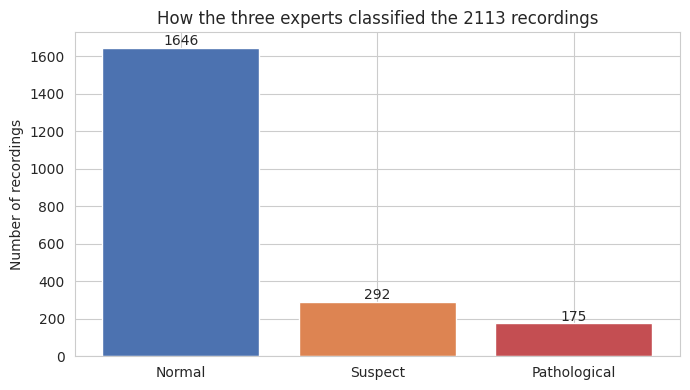

In [7]:
# The target and what its codes mean
HEALTH_NAMES = {1: 'Normal', 2: 'Suspect', 3: 'Pathological'}
fetal['fetal_health'] = fetal['fetal_health'].astype(int)

counts = fetal['fetal_health'].value_counts().sort_index()
share = (fetal['fetal_health'].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({'Recordings': counts.values, 'Share %': share.values},
                   index=[HEALTH_NAMES[c] for c in counts.index]))

plt.figure(figsize=(7, 4))
plt.bar([HEALTH_NAMES[c] for c in counts.index], counts.values,
        color=['#4c72b0', '#dd8452', '#c44e52'])
for i, value in enumerate(counts.values):
    plt.text(i, value + 15, str(value), ha='center')
plt.title('How the three experts classified the 2113 recordings')
plt.ylabel('Number of recordings')
plt.tight_layout()
plt.show()

The chart counts the recordings in each class: 1646 normal, 292 suspect and 175
pathological, that is 77.9, 13.8 and 8.3 percent.

That distribution is the reference for everything that follows and it sets the
floor of the evaluation. A model that answered normal to every trace, without
looking at a single feature, would be right 77.9 percent of the time. So an
accuracy of 0.78 is not a result, it is the starting point, and any accuracy
below about 0.85 would be worse than it looks.

The imbalance also has a direct effect on how the SVM is fitted. The model is
trained by minimising a penalty summed over the misclassified records, and with
1646 normal recordings against 175 pathological ones that sum is dominated by the
normal class. Giving up a few pathological records is cheaper than giving up many
normal ones, so the boundary gets drawn where it protects the majority and the
small classes lose territory. The modelling section corrects that with
`class_weight` and then measures whether the correction was worth anything.

Finally, 175 pathological recordings is enough to learn from but not many, and
after the split about 44 of them will be left to judge the model on. Every recall
reported for that class in the evaluation is computed on those 44 cases, and a
single recording moves it by more than two points.

## Data Exploration (CRISP-DM 2)

Two questions have to be answered here. Which of the 21 features actually
separate a healthy trace from a distressed one, and on what numeric scale each of
them is written, because an SVM with a radial kernel measures the distance
between two recordings and a distance is dominated by whichever column is written
in the largest numbers.

In [8]:
# Summary of the 21 features
fetal.drop(columns='fetal_health').describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
baseline value,2113.0,133.3048,9.8375,106.0,126.000,133.000,140.000,160.000
accelerations,2113.0,0.0032,0.0039,0.0,0.000,0.002,0.006,0.019
fetal_movement,2113.0,0.0095,0.0468,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2113.0,0.0044,0.0029,0.0,0.002,0.005,0.007,0.015
light_decelerations,2113.0,0.0019,0.0030,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2113.0,0.0000,0.0001,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2113.0,0.0002,0.0006,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2113.0,46.9938,17.1778,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2113.0,1.3350,0.8844,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2113.0,9.7951,18.3371,0.0,0.000,0.000,11.000,91.000


Reading down the table, the 21 features fall into the three groups the loading
section described, and the groups are written on scales that have nothing to do
with each other.

The histogram columns are the large ones. `histogram_width` runs from 3 to 180
with a standard deviation of 39.0, `histogram_min` from 50 to 159,
`histogram_variance` from 0 to 269 and `baseline value` from 106 to 160 beats per
minute, which is the physiological range of a fetal heart.

The variability columns are middling. `abnormal_short_term_variability` is a
percentage running from 12 to 87 with a mean of 47, and
`percentage_of_time_with_abnormal_long_term_variability` runs from 0 to 91 with a
mean of 9.8 and a median of 0, so more than half the recordings have none of it.

The rate columns are tiny. `accelerations` spans 0 to 0.019,
`prolongued_decelerations` 0 to 0.005 and `severe_decelerations` 0 to 0.001, with
a standard deviation of 0.000057. Between that column and `histogram_width` there
is a factor of about 680000 in spread, and it is entirely a matter of units:
events per second against beats per minute.

The exploration below shows that the tiny columns are among the most informative
in the file, which is why the preparation section treats the scaling as the
decision it is rather than a formality.

prolongued_decelerations                                  0.487
abnormal_short_term_variability                           0.470
percentage_of_time_with_abnormal_long_term_variability    0.422
accelerations                                            -0.364
histogram_mode                                           -0.254
histogram_mean                                           -0.230
mean_value_of_long_term_variability                      -0.226
histogram_median                                         -0.208
histogram_variance                                        0.208
uterine_contractions                                     -0.205
baseline value                                            0.146
histogram_tendency                                       -0.136
severe_decelerations                                      0.132
mean_value_of_short_term_variability                     -0.101
fetal_movement                                            0.088
histogram_width                         

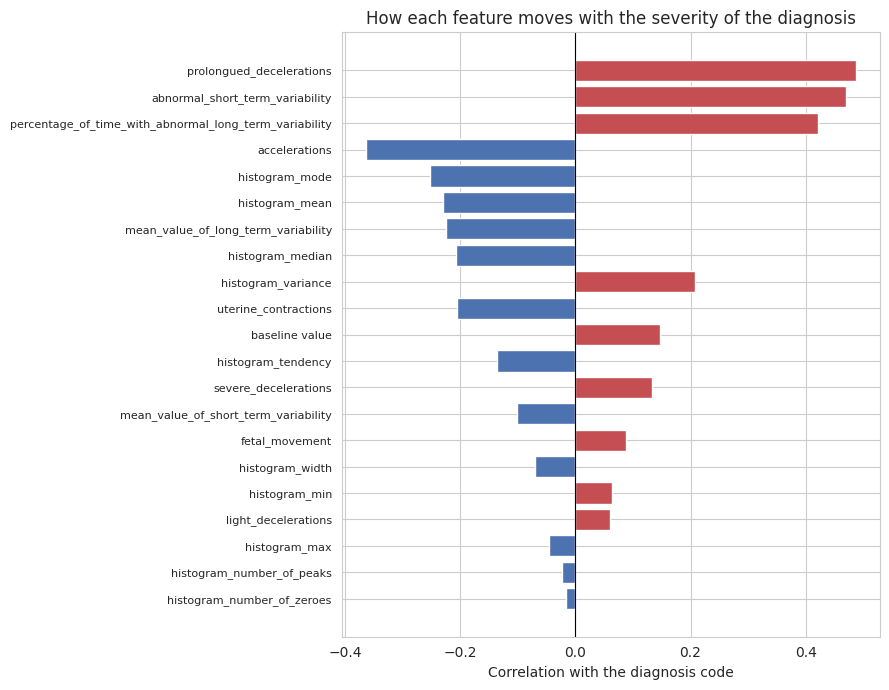

In [9]:
# Which features move with the diagnosis
target_correlation = (fetal.corr()['fetal_health'].drop('fetal_health')
                      .sort_values(key=abs, ascending=False))
print(target_correlation.round(3))

plt.figure(figsize=(9, 7))
colors = ['#c44e52' if v > 0 else '#4c72b0' for v in target_correlation.values]
plt.barh(range(len(target_correlation)), target_correlation.values, color=colors)
plt.yticks(range(len(target_correlation)), target_correlation.index, fontsize=8)
plt.gca().invert_yaxis()
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation with the diagnosis code')
plt.title('How each feature moves with the severity of the diagnosis')
plt.tight_layout()
plt.show()

The chart gives the correlation of each feature with the diagnosis code, in red
when the feature grows with the severity and in blue when it falls. The measure
is crude here, since the code 1, 2, 3 is treated as a number when it is really an
ordering, but it ranks the columns usefully and the ranking is clinically
recognisable.

The four at the top are the ones an obstetrician would name. `prolongued
decelerations` at 0.49 is a heart rate that drops and stays down after a
contraction, the classic sign of a fetus that is not getting enough oxygen.
`abnormal_short_term_variability` at 0.47 and
`percentage_of_time_with_abnormal_long_term_variability` at 0.42 are the two
measures of a trace going flat, which is the other classic sign.
`accelerations` at -0.36 is the reassuring one: a fetus that speeds its heart
when it moves is a fetus with a working nervous system.

Below those four the correlations fall away sharply. The four strongest histogram
summaries, the mode, the mean, the median and the variance, sit between 0.21 and
0.25, and the remaining six fall from 0.14 down to almost nothing:
`histogram_number_of_peaks` at -0.023 and `histogram_number_of_zeroes` at -0.016
are effectively unrelated to the diagnosis on their own.

Two of the four strongest features, `prolongued_decelerations` and
`accelerations`, are among the smallest in the file, with standard deviations of
0.0006 and 0.0039. This is the tension the preparation section has to resolve.

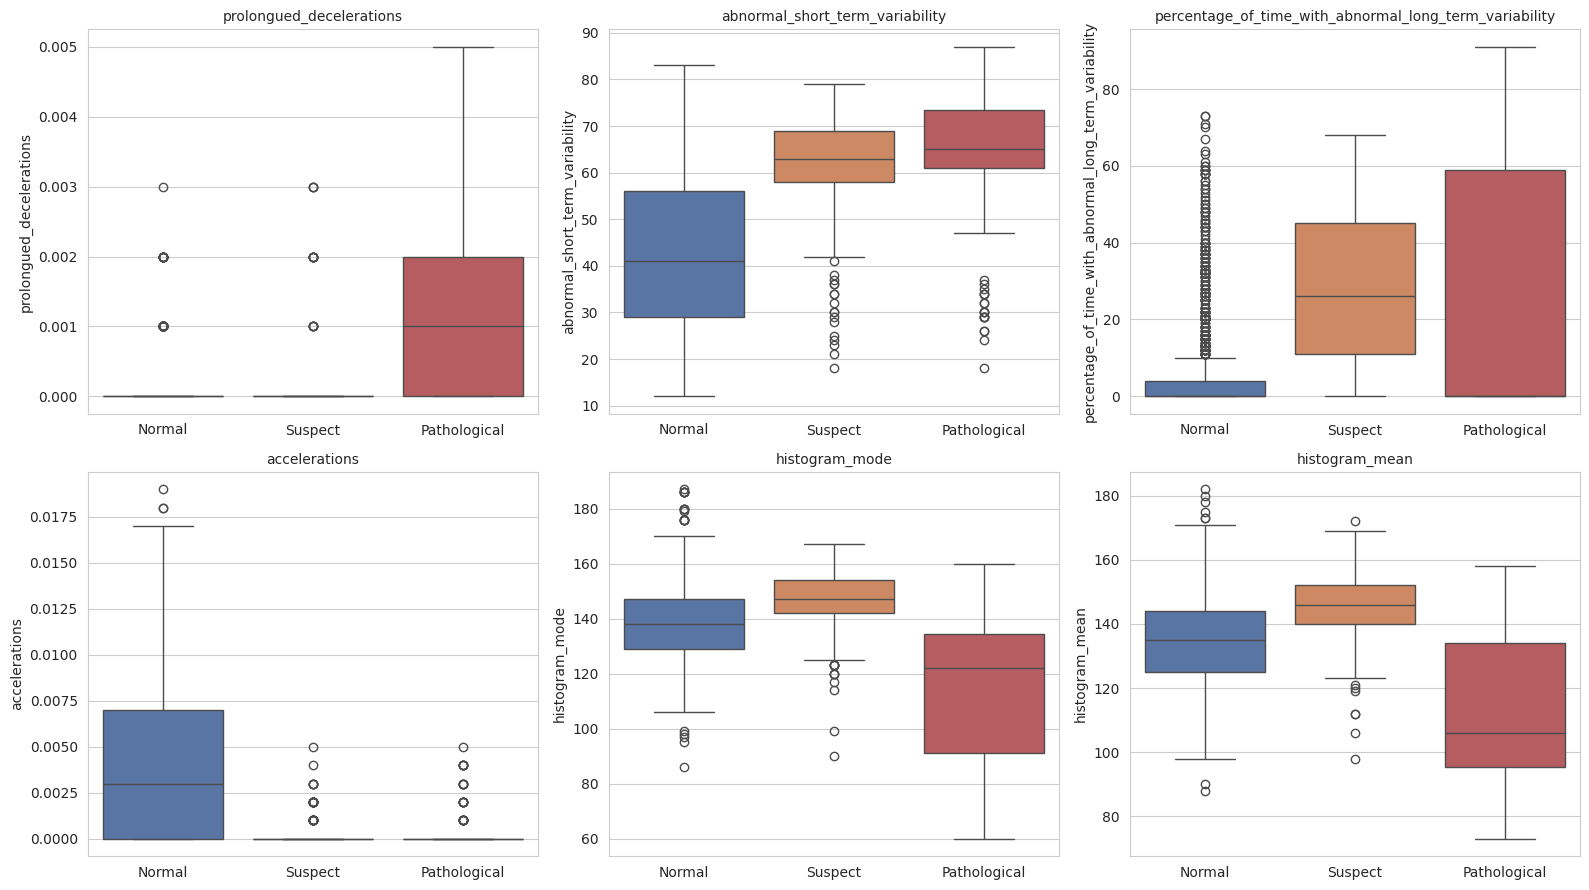

In [10]:
# The six most informative features, one panel each, split by diagnosis
top_features = list(target_correlation.head(6).index)
order = [1, 2, 3]
palette = {1: '#4c72b0', 2: '#dd8452', 3: '#c44e52'}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, column in zip(axes.ravel(), top_features):
    sns.boxplot(data=fetal, x='fetal_health', y=column, hue='fetal_health',
                order=order, palette=palette, ax=ax, legend=False)
    ax.set_xticks(range(3))
    ax.set_xticklabels([HEALTH_NAMES[c] for c in order])
    ax.set_title(column, fontsize=10)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Each panel is a box plot of one feature with one box per diagnosis. The box holds
the middle half of the recordings of that class, the line inside is the median,
the whiskers reach the values still close to the box and the points beyond them
are the recordings that sit far from the rest of their group.

The panels show why this problem is not linearly separable and why the second
class is the hard one.

`abnormal_short_term_variability` separates normal from the other two cleanly
enough: the normal box sits low, at a median of 41, and both abnormal classes sit
high, at 63 and 65. But it does not separate suspect from pathological at all,
since their boxes cover each other almost exactly.

`percentage_of_time_with_abnormal_long_term_variability` does something different
and more awkward. Only the suspect class lifts off zero, at a median of 26; the
normal and the pathological recordings both sit at a median of exactly 0, and on
the means the ordering is 5.1 for normal, 28.8 for suspect and 22.6 for
pathological. So this column does not rank the three classes by severity at all,
it singles out the middle one, and any model that assumed the three classes lie
along a line in this direction would be defeated by it.

`prolongued_decelerations` is the sharpest of the six and the box plot barely
shows why, because the column is zero in most recordings and the boxes collapse
onto the axis. The next cell reads it as a frequency instead.

Taken together the panels say that no single feature separates the three classes,
and that the boundaries are not parallel: normal against the rest runs one way,
suspect against pathological runs another. That is a curved boundary in 21
dimensions, and it is the argument for a kernel rather than a linear model.

In [11]:
# Three of the strongest features are counts of events that usually do not
# happen, so what matters is how often they happen at all
signals = ['prolongued_decelerations', 'accelerations', 'severe_decelerations']
presence = pd.DataFrame({
    column: fetal.groupby('fetal_health')[column].apply(lambda s: (s > 0).mean() * 100)
    for column in signals
}).round(1)
presence.index = [HEALTH_NAMES[c] for c in presence.index]
print("Percentage of recordings in which the event occurs at least once:")
print(presence)

print("\nAverage rate per second when it does occur:")
print(pd.DataFrame({
    column: fetal[fetal[column] > 0].groupby('fetal_health')[column].mean()
    for column in signals
}).round(5).rename(index=HEALTH_NAMES))

Percentage of recordings in which the event occurs at least once:
              prolongued_decelerations  accelerations  severe_decelerations
Normal                             4.2           69.9                   0.1
Suspect                            5.1           15.8                   0.0
Pathological                      53.7           17.1                   3.4

Average rate per second when it does occur:
              prolongued_decelerations  accelerations  severe_decelerations
fetal_health                                                               
Normal                         0.00123        0.00572                 0.001
Suspect                        0.00187        0.00176                   NaN
Pathological                   0.00238        0.00230                 0.001


Read as frequencies these three columns become the clearest signal in the
dataset.

A prolonged deceleration occurs in 4.2 percent of the normal recordings and 5.1
percent of the suspect ones, and in 53.7 percent of the pathological ones. So the
presence of that single event multiplies the plausibility of a pathological
reading by more than ten, which is exactly what the clinical literature says it
should do.

Accelerations run the other way and are just as sharp. A normal recording
contains at least one in 69.9 percent of cases; a suspect recording in 15.8
percent and a pathological one in 17.1 percent. A trace with no acceleration at
all is not necessarily distressed, but a trace with accelerations is almost
certainly fine.

Severe decelerations are the rarest event in the file: 3.4 percent of the
pathological recordings, 0.1 percent of the normal ones, that is one recording,
and none at all among the suspect ones, which is why the second table has no
value to report there. The column is non zero in exactly seven rows of the whole
dataset, six of them pathological, and it carries its information in those seven
rows and nowhere else. A model that ignored it would lose almost nothing on
average and would lose exactly the cases that matter most.

All three of these columns have standard deviations between 0.00006 and 0.004.
They are the smallest numbers in the file and they carry the most direct evidence
in it.

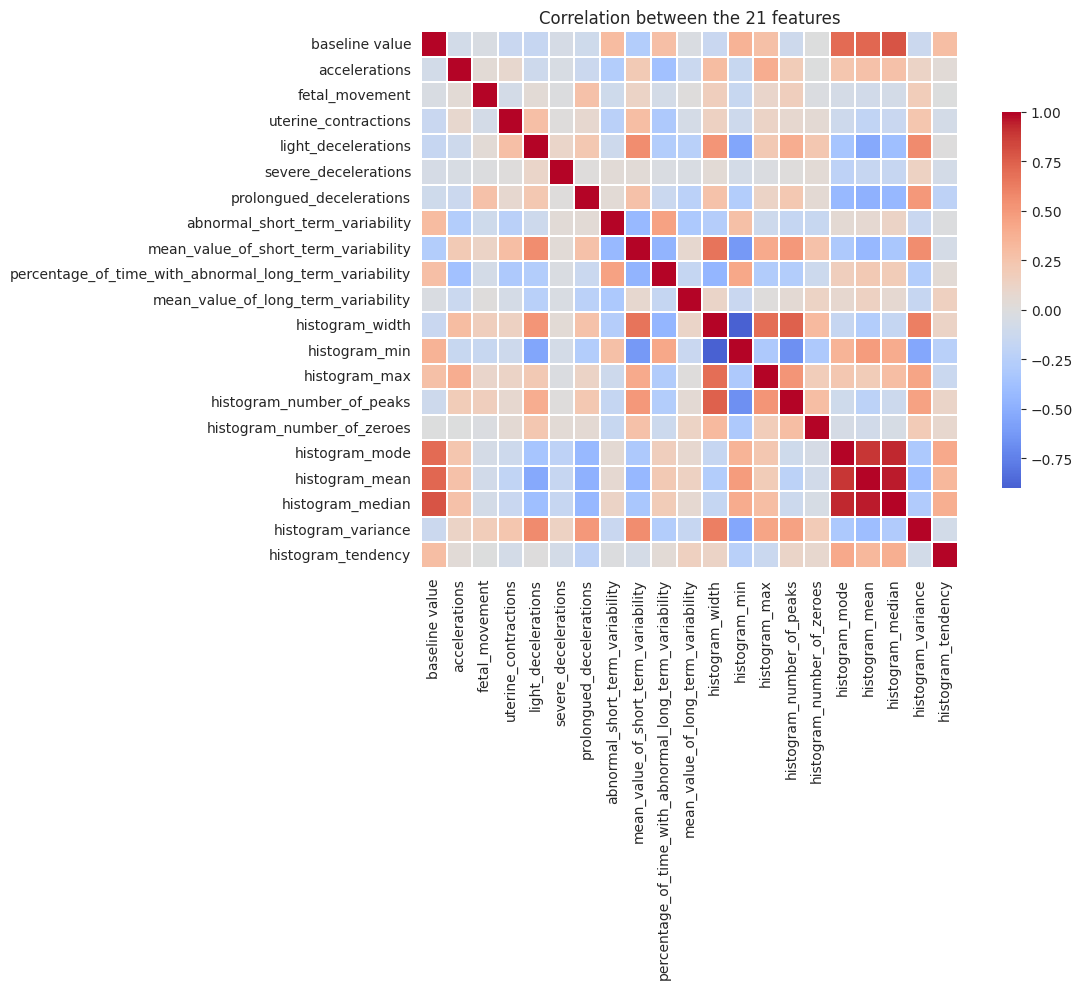

Pairs of features correlated above 0.7 in absolute value:
   histogram_mean / histogram_median : 0.948
   histogram_mode / histogram_median : 0.933
   histogram_width / histogram_min : -0.899
   histogram_mode / histogram_mean : 0.893
   baseline value / histogram_median : 0.788
   histogram_width / histogram_number_of_peaks : 0.747
   baseline value / histogram_mean : 0.722
   baseline value / histogram_mode : 0.708


In [12]:
# How the 21 features relate to each other
plt.figure(figsize=(13, 10))
sns.heatmap(fetal.drop(columns='fetal_health').corr(), cmap='coolwarm', center=0,
            square=True, linewidths=0.3, cbar_kws={'shrink': 0.7})
plt.title('Correlation between the 21 features')
plt.tight_layout()
plt.show()

# The pairs that say almost the same thing
correlations = fetal.drop(columns='fetal_health').corr()
strong = []
for i in range(len(correlations)):
    for j in range(i + 1, len(correlations)):
        if abs(correlations.iloc[i, j]) > 0.7:
            strong.append((correlations.index[i], correlations.columns[j],
                           round(correlations.iloc[i, j], 3)))
print("Pairs of features correlated above 0.7 in absolute value:")
for pair in sorted(strong, key=lambda t: -abs(t[2])):
    print("  ", pair[0], "/", pair[1], ":", pair[2])

The map is dominated by a red block in its lower right corner, and the listing
names it: the histogram summaries repeat each other. `histogram_mean` and
`histogram_median` correlate at 0.95, `histogram_mode` and `histogram_median` at
0.93, `histogram_mode` and `histogram_mean` at 0.89, and all three correlate
above 0.7 with `baseline value`. That is arithmetic rather than biology, since
the mean, the median and the mode of the same heart rate histogram have to move
together, and the baseline is a fourth way of saying where that histogram sits.

The second pair is `histogram_width` against `histogram_min` at -0.90, which is
the same tautology: the width is the maximum minus the minimum, and the maximum
varies much less than the minimum, so a low minimum is a wide histogram almost by
definition. `histogram_width` and `histogram_number_of_peaks` follow at 0.75.

So of the ten histogram columns, roughly half carry independent information and
the rest restate them: the mode, the mean and the median are one measurement
written three times, and the width and the minimum are largely a second.

No column is removed for it, and the reason is worth stating because with a
different model the decision would go the other way. Correlated predictors break
models that estimate one coefficient per column, because the coefficients become
unstable and uninterpretable when two columns say the same thing. An SVM with a
radial kernel estimates no coefficient per column; it works from distances
between records, and a repeated measurement affects a distance only by weighting
that property more heavily. Since the repetition here is concentrated in the
histogram block, which the correlation ranking already showed to be the weakest
group, the practical damage is small, and dropping columns by hand would risk
losing the part of them that is not redundant.

Share of the variation kept by each axis: [0.289 0.167]  total: 0.456


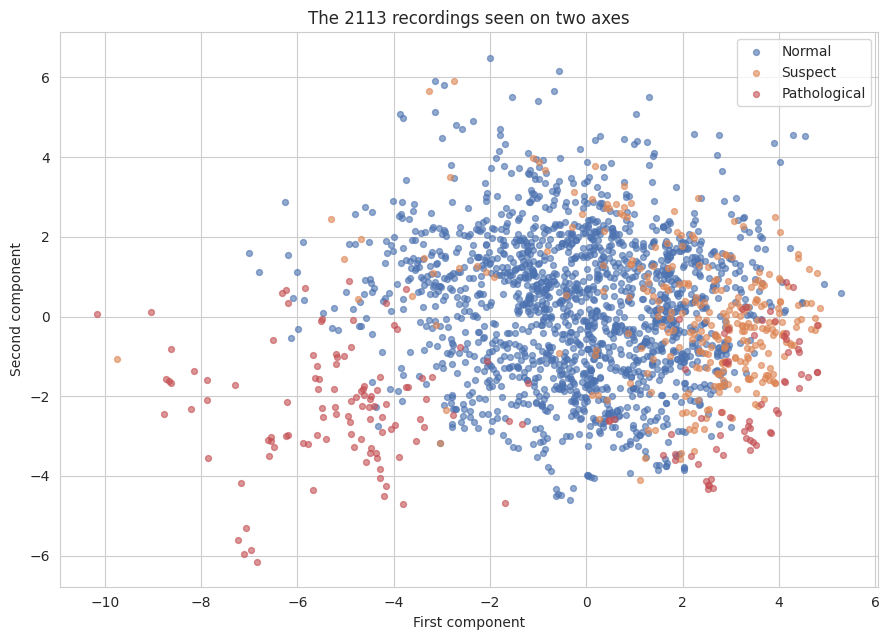

In [13]:
# The 21 features compressed to two axes so the dataset fits in one picture.
# This is a view, not a preparation step: the model reads all 21
FEATURES = [c for c in fetal.columns if c != 'fetal_health']
standardised = StandardScaler().fit_transform(fetal[FEATURES])
projection = PCA(n_components=2).fit(standardised)
coords = projection.transform(standardised)
print("Share of the variation kept by each axis:",
      projection.explained_variance_ratio_.round(3),
      " total:", round(projection.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(9, 6.5))
for c in [1, 2, 3]:
    mask = (fetal['fetal_health'] == c).values
    plt.scatter(coords[mask, 0], coords[mask, 1], s=18, alpha=0.6,
                color=palette[c], label=HEALTH_NAMES[c])
plt.xlabel('First component')
plt.ylabel('Second component')
plt.title('The 2113 recordings seen on two axes')
plt.legend()
plt.tight_layout()
plt.show()

The plot compresses the 21 features into the two directions along which the
recordings differ the most. Those two axes keep 45.6 percent of the variation, so
more than half the information is missing from the picture and it can only be
read as a hint.

Even reduced this way the structure is visible. The normal recordings form a
dense mass, the pathological ones sit mostly along one edge of it, and the
suspect ones lie in between, overlapping both. That middle position is the
central difficulty of the problem: suspect is not a third kind of trace so much
as the region where the experts were not prepared to say normal and not prepared
to say pathological, so it borders the other two on both sides and has a clean
frontier with neither.

For an SVM this picture predicts the shape of the result. A boundary can be drawn
around the normal mass, but it will have to curve, and the errors will
concentrate on the suspect class, which has other classes on both of its sides.
The evaluation confirms both.

## Data Preparation (CRISP-DM 3)

Nothing has to be imputed, encoded or removed: the file is complete, entirely
numeric, and the duplicates are gone. What remains are the two decisions an SVM
with a radial kernel actually depends on, the scale of the columns and the split.

In [14]:
# A radial kernel reads exp(-gamma * squared distance between two records), and a
# squared distance is the sum of the squared differences of the 21 columns, so
# each column contributes in proportion to its variance. This is that share,
# before and after scaling
variances = fetal[FEATURES].var()
raw_share = variances / variances.sum() * 100          # kept unrounded for the sums
weight = pd.DataFrame({
    'Standard deviation': fetal[FEATURES].std().round(4),
    'Weight in a raw distance %': raw_share.round(3),
    'Weight after scaling %': round(100 / len(FEATURES), 2),
}).sort_values('Weight in a raw distance %', ascending=False)
print(weight)

rates = ['accelerations', 'fetal_movement', 'uterine_contractions',
         'light_decelerations', 'severe_decelerations', 'prolongued_decelerations']
print("\nThe three largest columns together:",
      round(raw_share.sort_values(ascending=False).head(3).sum(), 1), "%")
print("The six event rate columns together:",
      format(raw_share[rates].sum(), '.2e'), "%")
print("  of which prolongued_decelerations:",
      format(raw_share['prolongued_decelerations'], '.2e'), "%")

                                                    Standard deviation  Weight in a raw distance %  Weight after scaling %
histogram_width                                                39.0077                      30.111                    4.76
histogram_min                                                  29.5623                      17.294                    4.76
histogram_variance                                             29.0388                      16.687                    4.76
percentage_of_time_with_abnormal_long_term_vari...             18.3371                       6.654                    4.76
histogram_max                                                  17.9452                       6.373                    4.76
abnormal_short_term_variability                                17.1778                       5.839                    4.76
histogram_mode                                                 16.4020                       5.324                    4.76
histogram_mean  

This table is the argument for scaling, and on this dataset it is not a close
call.

Read on raw values, three columns own two thirds of every distance:
`histogram_width` at 30.1 percent, `histogram_min` at 17.3 and
`histogram_variance` at 16.7, together 64.1 percent. Those are the three columns
written in the largest numbers, and the correlation ranking put two of them near
the bottom of the file for usefulness.

At the other end, the six event rate columns together contribute 4.4 hundred
thousandths of one percent of a distance, printed under the table because the
number does not survive rounding. That is not a small weight, it is no weight at
all: to a radial kernel reading raw values, two recordings that differ by every
acceleration and every prolonged deceleration are the same recording. And
`prolongued_decelerations` is the feature most correlated with the diagnosis in
the whole file, present in 54 percent of pathological traces and 4 percent of
normal ones.

So an unscaled SVM on this dataset would be classifying fetal distress from the
width of a histogram while ignoring the decelerations entirely. The modelling
section fits one and measures the cost.

`StandardScaler` divides each column by its own standard deviation, which makes
every column contribute 1/21, that is 4.76 percent, of a distance. That is not
the perfect weighting either, since it gives `histogram_number_of_zeroes` the
same say as `prolongued_decelerations`, but it is a neutral starting point that
lets the model decide from the data instead of from the units, and the parameter
`gamma` then controls how far a record's influence reaches in that rescaled
space.

The scaler is fitted inside a `Pipeline` throughout, so in every cross validation
fold the mean and the standard deviation come from the training part of that fold
only. Fitting it once on the whole dataset would let the test records influence
the transformation applied to the training data and would inflate every score
that follows.

In [15]:
# Predictors and response
X = fetal[FEATURES]
y = fetal['fetal_health']

# 75 / 25 split, stratified so the three classes keep their proportions on both
# sides. Without stratify the 175 pathological records could land unevenly and
# the recall of that class would measure the split rather than the model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print("Training recordings:", len(X_train), " Test recordings:", len(X_test))
print()
print(pd.DataFrame({
    'Training': y_train.value_counts().sort_index(),
    'Test': y_test.value_counts().sort_index(),
    'Training %': (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    'Test %': (y_test.value_counts(normalize=True).sort_index() * 100).round(1),
}).rename(index=HEALTH_NAMES))

Training recordings: 1584  Test recordings: 529

              Training  Test  Training %  Test %
fetal_health                                    
Normal            1234   412        77.9    77.9
Suspect            219    73        13.8    13.8
Pathological       131    44         8.3     8.3


The split leaves 1584 recordings to learn from and 529 to be judged on, with the
same 77.9 / 13.8 / 8.3 composition on both sides.

The numbers that matter for reading the evaluation are the small ones. The
training set holds 131 pathological recordings, which is what the model has to
learn that class from, and the test set holds 44, which is what every figure
reported for that class is computed on. One recording is 2.3 points of recall
there, so the difference between a recall of 0.75 and one of 0.80 is two cases.

The 529 test recordings are not touched again until the evaluation section. The
kernel, the two hyperparameters and the class weighting are all chosen by five
fold cross validation inside the 1584 training recordings.

## Model of AI (CRISP-DM 4: Modelling)

### How a Support Vector Machine works

An SVM separates two classes with a boundary, but not any boundary. Among all the
surfaces that separate the training data it looks for the one that leaves the
widest empty corridor on either side, and the records that sit on the edge of
that corridor, the **support vectors**, are the only ones that define it. Moving
a record far from the boundary changes nothing at all; the model is determined by
the difficult cases at the frontier.

Three things have to be decided, and this section decides all three on the
training set.

**The kernel.** A linear SVM can only draw a flat boundary. The kernel trick
replaces the distance between two records with a function of it, which is
equivalent to drawing a flat boundary in a much larger space and a curved one in
the original. The radial basis kernel used here is `exp(-gamma * d²)`, where `d`
is the distance between two records, so a training record's influence fades with
distance and the boundary can wrap around a region.

**C**, the regularisation constant. It is the price paid for each record on the
wrong side of the corridor. A small C tolerates mistakes and keeps the corridor
wide, giving a smooth boundary that may underfit; a large C insists on
classifying the training data correctly and lets the corridor narrow, which bends
the boundary around individual records and risks memorising them.

**gamma**, how far the influence of a single record reaches. A small gamma makes
each record influence a wide region and produces an almost linear boundary; a
large gamma makes the influence local and lets the boundary form tight pockets
around individual records. C and gamma work against each other and have to be
chosen together, which is what the grid below does.

The problem has three classes and an SVM separates two, so scikit-learn fits one
model per pair, three in total, and lets them vote. That happens automatically
and is the reason the fitted model carries support vectors for each class
separately.

In [16]:
# Five fold stratified cross validation, used for every comparison in this section
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def svm_pipeline(**settings):
    """A scaler and an SVM, so the scaler is refitted inside every fold."""
    return Pipeline([('scaler', StandardScaler()),
                     ('svc', SVC(class_weight='balanced',
                                 random_state=RANDOM_STATE, **settings))])


# A first model: the linear kernel, to see what a flat boundary can do here
linear_baseline = svm_pipeline(kernel='linear', C=1)
accuracy = cross_val_score(linear_baseline, X_train, y_train, cv=cv, scoring='accuracy')
macro_f1 = cross_val_score(linear_baseline, X_train, y_train, cv=cv, scoring='f1_macro')

print("Linear SVM, C=1, balanced class weights")
print("  accuracy:", round(accuracy.mean(), 4), "+/-", round(accuracy.std(), 4))
print("  macro F1:", round(macro_f1.mean(), 4), "+/-", round(macro_f1.std(), 4))
print("  answering Normal to everything would give:",
      round(y_train.value_counts(normalize=True).max(), 4))

Linear SVM, C=1, balanced class weights
  accuracy: 0.8662 +/- 0.025
  macro F1: 0.7913 +/- 0.0389
  answering Normal to everything would give: 0.779


A linear SVM reaches an accuracy of 0.866 and a macro F1 of 0.791, against a
floor of 0.779 for answering normal to every recording.

Both numbers are reported throughout this section and they measure different
things. The accuracy counts every recording once, so with 1234 normal recordings
out of 1584 it is largely a report on the normal class. The macro F1 computes the
F1 of each class separately and averages the three equally, so the 131
pathological recordings weigh as much as the 1234 normal ones. Since the entire
purpose of the model is the two small classes, macro F1 is the criterion used to
select everything that follows, and the accuracy is reported alongside it.

The linear result is a real starting point rather than a failure: eight and a
half points of accuracy above the floor means a flat boundary already captures
much of the structure. The next cells measure how much a curved one adds.

         Macro F1  Accuracy
C                          
0.01       0.6718    0.7822
0.10       0.7525    0.8352
1.00       0.8340    0.8857
10.00      0.8593    0.9066
100.00     0.8638    0.9198
1000.00    0.8618    0.9249


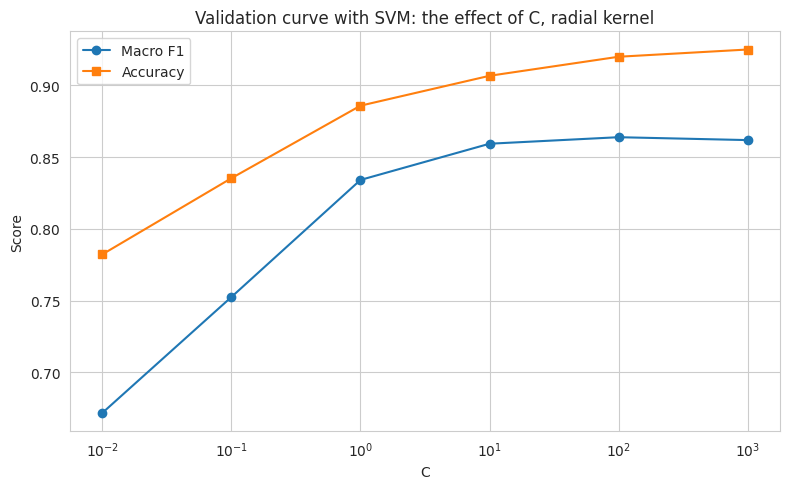

In [17]:
# The effect of C on a radial kernel, drawn on a logarithmic axis
C_values = [0.01, 0.1, 1, 10, 100, 1000]
curve_f1, curve_accuracy = [], []
for C in C_values:
    model = svm_pipeline(kernel='rbf', C=C, gamma='scale')
    curve_f1.append(cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro').mean())
    curve_accuracy.append(cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy').mean())

print(pd.DataFrame({'C': C_values,
                    'Macro F1': np.round(curve_f1, 4),
                    'Accuracy': np.round(curve_accuracy, 4)}).set_index('C'))

plt.figure(figsize=(8, 5))
plt.semilogx(C_values, curve_f1, marker='o', label='Macro F1')
plt.semilogx(C_values, curve_accuracy, marker='s', label='Accuracy')
plt.xlabel('C')
plt.ylabel('Score')
plt.title('Validation curve with SVM: the effect of C, radial kernel')
plt.legend()
plt.tight_layout()
plt.show()

The curve is the classic validation curve for C, with C on a logarithmic axis
because the useful values span five orders of magnitude.

At C = 0.01 the model is badly underfitted, at a macro F1 of 0.672. The penalty
for a misclassified record is so small that the widest corridor wins outright,
the boundary is nearly flat and the small classes are given away. From there the
curve climbs steeply, 0.753 at C = 0.1 and 0.834 at C = 1, then flattens: 0.859
at C = 10, 0.864 at C = 100 and 0.862 at C = 1000.

So the model improves by nineteen points as C rises from 0.01 to 100 and then
stops. The flattening is what matters: past C = 100 the boundary is already
following the training data as closely as it usefully can, and the small decline
at C = 1000 is the beginning of the overfitting the parameter exists to control.
The accuracy curve keeps creeping up to 0.925 at C = 1000 while the macro F1
falls, which is the same trade the class imbalance produces everywhere in this
notebook: a tighter fit around the majority class buys accuracy and costs the
small ones.

C was varied here with `gamma='scale'`, the default. The two parameters interact,
so the next cell searches them together rather than fixing one.

In [18]:
# Each kernel tuned on its own grid, so the comparison between them is fair.
# Every configuration is judged on macro F1 with the same five folds
searches = {}
kernel_grids = {
    'linear': ({'svc__C': [0.01, 0.1, 1, 10, 100]},
               {'kernel': 'linear'}),
    'rbf':    ({'svc__C': [0.1, 1, 10, 100, 1000],
                'svc__gamma': [0.001, 0.01, 0.05, 0.1, 'scale']},
               {'kernel': 'rbf'}),
    'poly':   ({'svc__C': [0.1, 1, 10, 100],
                'svc__gamma': [0.01, 0.05, 0.1, 'scale'],
                'svc__degree': [2, 3]},
               {'kernel': 'poly'}),
}

for name, (grid, fixed) in kernel_grids.items():
    search = GridSearchCV(svm_pipeline(**fixed), grid, cv=cv,
                          scoring='f1_macro', n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(name.ljust(7), "best macro F1:", round(search.best_score_, 4),
          "  with", search.best_params_)

winner = max(searches, key=lambda name: searches[name].best_score_)
print("\nBest kernel:", winner)

linear  best macro F1: 0.8003   with {'svc__C': 100}
rbf     best macro F1: 0.8749   with {'svc__C': 100, 'svc__gamma': 0.1}
poly    best macro F1: 0.864   with {'svc__C': 10, 'svc__degree': 3, 'svc__gamma': 0.1}

Best kernel: rbf


Tuned on its own grid, each kernel gives its best.

The radial kernel wins at a macro F1 of 0.875 with C = 100 and gamma = 0.1. The
polynomial kernel of degree 3 follows at 0.864 and the linear one comes last at
0.800, even after C was raised to 100 for it.

The seven and a half point gap between the linear and the radial kernel is the
answer to the question the exploration raised. A flat boundary cannot express
what the box plots showed, that
`percentage_of_time_with_abnormal_long_term_variability` is highest for the
suspect class rather than the pathological one, so the three classes do not lie
along a line in that direction. A curved boundary can wrap around the normal
region and leave both abnormal classes outside it in different directions, and
that is worth seven points here.

That the polynomial kernel lands close to the radial one is a useful check rather
than a disappointment. Two different families of curved boundary agree on roughly
the same level of performance, which suggests the limit is in the data rather
than in the choice of kernel.

Cross validated macro F1 for each pair (rows C, columns gamma):
param_svc__gamma   0.001    0.01    0.05     0.1   scale
param_svc__C                                            
0.1               0.6860  0.7377  0.7535  0.7399  0.7525
1.0               0.7555  0.7984  0.8297  0.8397  0.8340
10.0              0.7905  0.8344  0.8595  0.8649  0.8593
100.0             0.8097  0.8464  0.8650  0.8749  0.8638
1000.0            0.8332  0.8516  0.8627  0.8569  0.8618


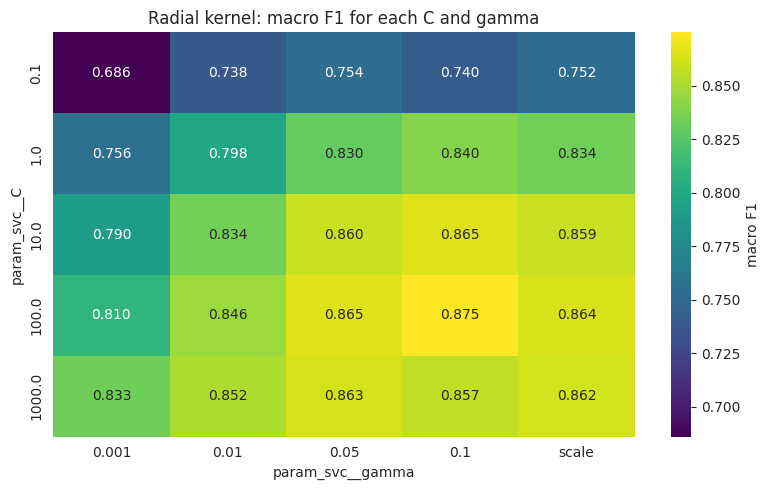

In [19]:
# The radial kernel's grid in full: how C and gamma trade against each other
rbf_results = pd.DataFrame(searches['rbf'].cv_results_)
table = rbf_results.pivot_table(index='param_svc__C', columns='param_svc__gamma',
                                values='mean_test_score')
print("Cross validated macro F1 for each pair (rows C, columns gamma):")
print(table.round(4))

plt.figure(figsize=(8, 5))
sns.heatmap(table, annot=True, fmt='.3f', cmap='viridis',
            cbar_kws={'label': 'macro F1'})
plt.title('Radial kernel: macro F1 for each C and gamma')
plt.tight_layout()
plt.show()

The heat map is the whole grid, with C down the side and gamma along the top, and
it shows the two parameters compensating for each other exactly as the theory
says they should.

The worst corner is the top left, C = 0.1 with gamma = 0.001, at 0.686: a
tolerant penalty combined with an influence that reaches across the whole space
gives a boundary too smooth to separate anything. Improvement runs diagonally
down and to the right. Along the bottom row, at C = 1000, raising gamma from
0.001 to 0.05 gains three points; down the gamma = 0.1 column, raising C from 0.1
to 100 gains thirteen.

The best cell is C = 100 with gamma = 0.1 at 0.875, and its neighbours sit within
one or two points of it, so the surface is flat near its top and the exact choice
is not critical. The far corner tells the other half of the story: at C = 1000 with
gamma = 0.1 the score falls back to 0.857, which is a boundary that has begun to
wrap itself around individual training records.

In [20]:
# Two decisions taken in the preparation and the setup, now measured at the
# chosen C and gamma. Every training record is classified by the folds that did
# not contain it, so no test data is used
best_C = searches['rbf'].best_params_['svc__C']
best_gamma = searches['rbf'].best_params_['svc__gamma']
print("Tuned setting: C =", best_C, " gamma =", best_gamma, "\n")

variants = {
    'scaled, balanced weights': svm_pipeline(kernel='rbf', C=best_C, gamma=best_gamma),
    'scaled, no class weights': Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(kernel='rbf', C=best_C, gamma=best_gamma,
                    random_state=RANDOM_STATE))]),
    'NOT scaled, tuned gamma': Pipeline([
        ('svc', SVC(kernel='rbf', C=best_C, gamma=best_gamma,
                    class_weight='balanced', random_state=RANDOM_STATE))]),
    # gamma='scale' sets gamma from the variance of the raw columns, so this
    # variant gets a gamma adapted to its own units instead of one tuned for
    # standardised data, which is the fairer comparison
    'NOT scaled, gamma=scale': Pipeline([
        ('svc', SVC(kernel='rbf', C=best_C, gamma='scale',
                    class_weight='balanced', random_state=RANDOM_STATE))]),
}

rows = []
for name, variant in variants.items():
    out_of_fold = cross_val_predict(variant, X_train, y_train, cv=cv)
    rows.append({
        'Variant': name,
        'Accuracy': round(accuracy_score(y_train, out_of_fold), 4),
        'Macro F1': round(f1_score(y_train, out_of_fold, average='macro'), 4),
        'Recall Suspect': round(recall_score(y_train, out_of_fold, labels=[2],
                                             average='macro'), 4),
        'Recall Pathological': round(recall_score(y_train, out_of_fold, labels=[3],
                                                  average='macro'), 4),
        'Precision Suspect': round(precision_score(y_train, out_of_fold, labels=[2],
                                                   average='macro'), 4),
    })
print(pd.DataFrame(rows).set_index('Variant').to_string())

Tuned setting: C = 100  gamma = 0.1 

                          Accuracy  Macro F1  Recall Suspect  Recall Pathological  Precision Suspect
Variant                                                                                             
scaled, balanced weights    0.9312    0.8757          0.7671               0.8397             0.7887
scaled, no class weights    0.9293    0.8726          0.7671               0.8321             0.7814
NOT scaled, tuned gamma     0.7923    0.3816          0.0502               0.0916             0.8462
NOT scaled, gamma=scale     0.8592    0.7965          0.8402               0.9160             0.5349


The table answers two questions with the same folds, and the two answers are very
different in size.

**Scaling.** The unscaled model is shown twice, because the answer depends on
what gamma it is given.

With the tuned gamma of 0.1 the macro F1 falls from 0.876 to 0.382 and the
accuracy to 0.792, barely above the 0.779 obtained by answering normal to
everything: the model recovers 9.2 percent of the pathological recordings and
5.0 percent of the suspect ones. That collapse is partly an artefact of the
comparison. A gamma of 0.1 was chosen for columns measured in standard
deviations; on raw columns that span hundreds of units it makes the influence of
a training record vanish within a fraction of a unit, so almost no record is
close to anything and the model falls back on the majority.

The fairer comparison is the last row, where `gamma='scale'` sets gamma from the
variance of the raw columns, here about 0.00001. That model works, at a macro F1
of 0.797 and an accuracy of 0.859, and it still loses eight points of macro F1
and seven of accuracy to the scaled one. The last three columns show how. It
finds more of the suspect and pathological recordings than the scaled model,
84.0 and 91.6 percent against 76.7 and 84.0, but it does so by raising many
normal recordings to suspect, and the precision of the suspect class falls to
0.535 against 0.789 when the columns are scaled. With three histogram
columns carrying two thirds of every raw distance, the kernel is reading the
shape of the histogram and little else, which is enough to separate the flat
traces from the rest and not enough to tell a suspect trace from a normal one.
Scaling remains the largest single effect in the notebook; measured fairly it is
eight points rather than fifty.

**Class weighting.** `class_weight='balanced'` multiplies the penalty for each
class by the inverse of its frequency, so a pathological record counts about nine
times a normal one. It gains 0.3 points of macro F1, 0.8757 against 0.8726, and
just under one point of recall on the pathological class, 0.840 against 0.832.
That is a real but small improvement, and honesty requires saying so rather than
presenting the weighting as the fix for the imbalance.

The reason it does so little here is C. At C = 100 the penalty for any
misclassified record is already high enough that the boundary is being pulled
towards the small classes anyway, and reweighting adds little on top. It is kept
because it costs nothing, it moves the recall of the class that matters in the
right direction, and it makes the model's behaviour less dependent on the exact
value of C. The real answer to the imbalance in this notebook is not the class
weight, it is the decision rule built in the evaluation section.

In [21]:
# The chosen model, refitted on the whole training set.
# probability=True makes SVC fit a calibration on top of the decision function,
# which the evaluation section needs for the ROC curves and the decision rule
model = svm_pipeline(kernel='rbf', C=best_C, gamma=best_gamma, probability=True)
model.fit(X_train, y_train)

support = model.named_steps['svc'].n_support_
print("Final model:", model.named_steps['svc'])
print("\nSupport vectors per class:", dict(zip([HEALTH_NAMES[c] for c in model.classes_],
                                               [int(s) for s in support])))
print("Total:", support.sum(), "of", len(X_train), "training recordings =",
      round(support.sum() / len(X_train) * 100, 1), "%")

Final model: SVC(C=100, class_weight='balanced', gamma=0.1, probability=True, random_state=1)

Support vectors per class: {'Normal': 248, 'Suspect': 114, 'Pathological': 77}
Total: 439 of 1584 training recordings = 27.7 %


The fitted model keeps 439 support vectors out of 1584 training recordings, 27.7
percent, split as 248 normal, 114 suspect and 77 pathological.

Those proportions describe the geometry of the problem better than any score. The
model discards 80 percent of the normal recordings as irrelevant to the boundary,
because they sit deep inside the normal region and moving them would change
nothing. It keeps 52 percent of the suspect recordings and 59 percent of the
pathological ones, because those classes sit on or near the frontier and nearly
every one of them helps define it.

This is the same conclusion the projection plot suggested, now measured on the
fitted model: the suspect class has no interior of its own, it is a border
region.

## Evaluation (CRISP-DM 5)

The 529 test recordings have taken part in no decision. The scaler was refitted
inside each fold, the kernel was chosen by comparing three tuned candidates on
cross validation, C and gamma came from a grid on the training set and the class
weighting was checked the same way. What follows is a single estimate on data
that influenced nothing.

In [22]:
# The model on data it has never seen
predictions = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Test macro F1:", round(f1_score(y_test, predictions, average='macro'), 4))
print("Answering Normal to everything would give:",
      round(y_test.value_counts(normalize=True).max(), 4))
print()
print("Cross validated estimate on the training set:",
      round(searches['rbf'].best_score_, 4), "macro F1")

Test accuracy: 0.9112
Test macro F1: 0.834
Answering Normal to everything would give: 0.7788

Cross validated estimate on the training set: 0.8749 macro F1


The model classifies 482 of the 529 test recordings correctly, an accuracy of
0.911 against a floor of 0.779, with a macro F1 of 0.834.

The macro F1 on the test set is four points below the 0.875 the cross validation
predicted. A drop in that direction is normal and is the reason the test set was
kept aside: the cross validated figure is the best of a hundred configurations
measured on the same folds, so it is optimistic by construction, and the honest
number is the one on data that took no part in the search. Four points is a
moderate optimism, not a sign that the selection overfitted the folds.

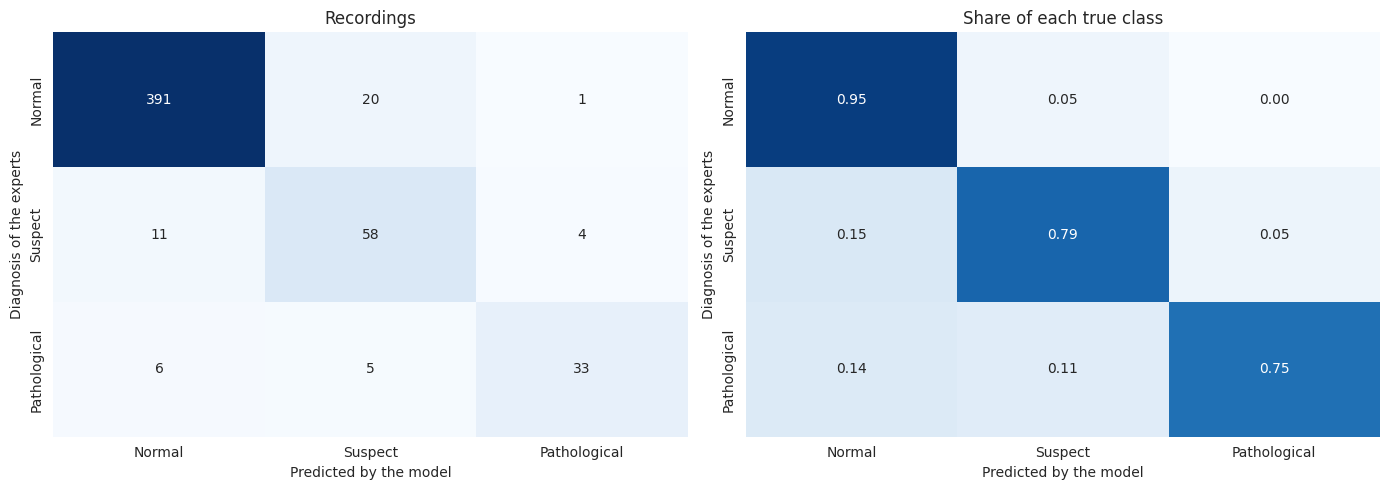

Pathological recordings sent to Normal: 6 of 44
Normal recordings raised to Suspect or Pathological: 21 of 412


In [23]:
# Where the errors are
matrix = confusion_matrix(y_test, predictions, labels=[1, 2, 3])
names = [HEALTH_NAMES[c] for c in [1, 2, 3]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=names, yticklabels=names)
axes[0].set_title('Recordings')
axes[0].set_xlabel('Predicted by the model')
axes[0].set_ylabel('Diagnosis of the experts')

by_row = matrix / matrix.sum(axis=1, keepdims=True)
sns.heatmap(by_row, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=names, yticklabels=names, vmin=0, vmax=1)
axes[1].set_title('Share of each true class')
axes[1].set_xlabel('Predicted by the model')
axes[1].set_ylabel('Diagnosis of the experts')
plt.tight_layout()
plt.show()

print("Pathological recordings sent to Normal:",
      int(matrix[2, 0]), "of", int(matrix[2].sum()))
print("Normal recordings raised to Suspect or Pathological:",
      int(matrix[0, 1] + matrix[0, 2]), "of", int(matrix[0].sum()))

The matrix has the experts' diagnosis down the side and the model's answer along
the top, so the diagonal is what it got right. The left panel counts recordings
and the right one turns each row into shares, which is the readable form when one
class is nine times another.

The normal class is handled well: 391 of 412 are recognised, and the 21 errors
are almost all a normal trace raised to suspect, which costs an unnecessary
check.

The suspect class is the weakest, 58 of 73, and its errors go in both directions,
11 down to normal and 4 up to pathological. That is exactly what the projection
plot and the support vector counts predicted for a class that is a border region
rather than a category with an interior.

The cell that matters clinically is the bottom left: **6 of the 44 pathological
recordings, 13.6 percent, are classified as normal.** Five more are called
suspect, which in practice still raises an alarm, so the model leaves 33
pathological traces correctly named, 5 flagged as suspicious and 6 sent through
as healthy.

Six missed cases out of 44 is the number the problem analysis said would decide
whether this model is usable, and as it stands it is too many. The last part of
this section addresses it directly instead of accepting it.

In [24]:
# The three classes in detail
print(classification_report(y_test, predictions,
                            target_names=names, digits=3))

              precision    recall  f1-score   support

      Normal      0.958     0.949     0.954       412
     Suspect      0.699     0.795     0.744        73
Pathological      0.868     0.750     0.805        44

    accuracy                          0.911       529
   macro avg      0.842     0.831     0.834       529
weighted avg      0.915     0.911     0.912       529



The report splits the 529 answers into three rates per class: precision is how
often the model is right when it gives that answer, recall is how much of the
class it found, and F1 balances the two.

Normal is nearly solved, at a precision of 0.958 and a recall of 0.949 on 412
recordings.

Pathological reaches a precision of 0.868 and a recall of 0.750 on 44. The
precision is the more useful of the two numbers here: when this model says
pathological, it is right about seven times out of eight, so its alarms are worth
acting on. The recall is the problem already named.

Suspect is the weakest class, precision 0.699 and recall 0.795. The low precision
means that of the 83 recordings the model calls suspect, 25 are not: 20 of them
are normal traces and 5 are pathological. In this application the first kind of
error is the acceptable direction to fail, since a suspect call means look again
rather than intervene, and the second kind still sends the recording to a
specialist.

The macro average, 0.842 precision and 0.831 recall, is the honest summary of a
model that is strong on the class that dominates the file and moderate on the two
that matter.

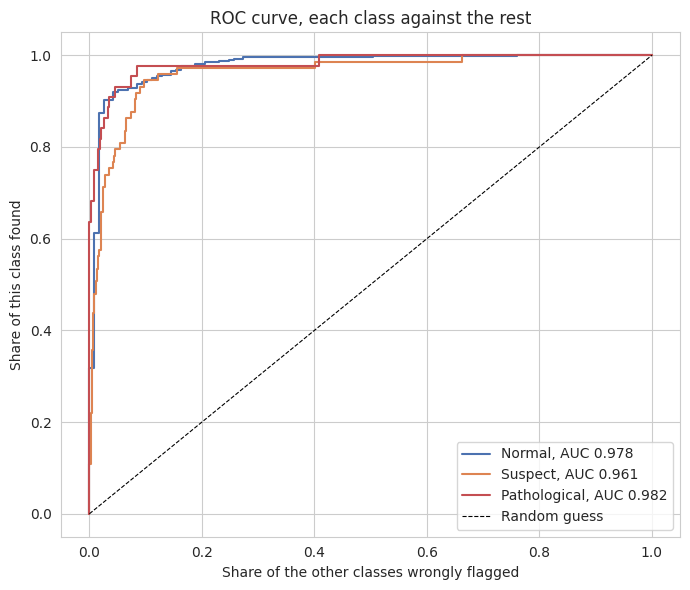

Macro average AUC: 0.9736
Records where predict() and the highest probability disagree: 10 of 529


In [25]:
# The model returns a score for each class, not only an answer. The ROC curve
# shows what every possible cut of that score would give, one class at a time
scores = model.predict_proba(X_test)

plt.figure(figsize=(7, 6))
for i, c in enumerate(model.classes_):
    actual = (y_test == c).astype(int)
    false_positive, true_positive, _ = roc_curve(actual, scores[:, i])
    auc = roc_auc_score(actual, scores[:, i])
    plt.plot(false_positive, true_positive, color=palette[c],
             label=HEALTH_NAMES[c] + ', AUC ' + str(round(auc, 3)))
plt.plot([0, 1], [0, 1], 'k--', linewidth=0.8, label='Random guess')
plt.xlabel('Share of the other classes wrongly flagged')
plt.ylabel('Share of this class found')
plt.title('ROC curve, each class against the rest')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print("Macro average AUC:",
      round(roc_auc_score(y_test, scores, multi_class='ovr', average='macro'), 4))

# SVC calibrates its probabilities separately from its decision function, so the
# class with the highest probability is not always the class predict() returns.
# This counts how often the two disagree on the test set
by_probability = model.classes_[scores.argmax(axis=1)]
print("Records where predict() and the highest probability disagree:",
      int((by_probability != predictions).sum()), "of", len(y_test))

Each curve takes one class against the other two and redraws the comparison at
every possible cut of the model's score: the horizontal axis is the share of the
other classes wrongly flagged and the vertical one the share of this class found.
The diagonal is what a coin flip would draw, and the area under a curve, the AUC,
is the probability that a record of the class receives a higher score than a
record that is not.

The three areas are 0.978 for normal, 0.961 for suspect and **0.982 for
pathological**, averaging 0.974.

That last number changes the reading of the whole evaluation. The recall of 0.750
for the pathological class is not the model failing to see those recordings, it
is the model seeing them and the default cut, which assigns each record to its
highest scoring class, placing them on the wrong side. An AUC of 0.982 says the
ranking is almost right: pathological recordings receive high pathological scores
even when another class scores higher still.

Where a ranking is that good and a decision that unbalanced, the fix is the
decision rather than the model, and the next cell rebuilds it.

A caveat belongs with these curves, and the last line of the cell measures it.
`SVC` produces probabilities by fitting a calibration on top of its decision
function, and that calibration is fitted by an internal cross validation, so the
class with the highest probability is not always the class `predict` returns. On
this test set the two disagree on 10 of the 529 records, which is under 2 percent
and does not change any conclusion, but it has to be declared: the confusion
matrix and the classification report above come from `predict`, while the curves
here and the decision rule below are read off `predict_proba`.

In [26]:
# The decision rule. Instead of taking the highest scoring class, a recording is
# flagged for review whenever its Normal score falls below a threshold, so the
# question becomes send this to a specialist or not.
# The threshold is chosen on the training folds, never on the test set
out_of_fold_scores = cross_val_predict(
    svm_pipeline(kernel='rbf', C=best_C, gamma=best_gamma, probability=True),
    X_train, y_train, cv=cv, method='predict_proba')
normal_score_train = out_of_fold_scores[:, list(model.classes_).index(1)]

rows = []
for threshold in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    flagged = normal_score_train < threshold
    rows.append({
        'Threshold': threshold,
        'Pathological flagged': round(((y_train == 3) & flagged).sum() / (y_train == 3).sum(), 3),
        'Suspect flagged': round(((y_train == 2) & flagged).sum() / (y_train == 2).sum(), 3),
        'Normal flagged (false alarm)': round(((y_train == 1) & flagged).sum() / (y_train == 1).sum(), 3),
        'Extra reviews per 100 normal': int(round(((y_train == 1) & flagged).sum()
                                                  / (y_train == 1).sum() * 100)),
    })
choices = pd.DataFrame(rows).set_index('Threshold')
print("Chosen on the training folds only:")
print(choices)

# The smallest threshold that misses no pathological recording on the folds
best_threshold = float(choices[choices['Pathological flagged'] >= 1.0].index.min())
print("\nSmallest threshold that misses no pathological recording on the folds:",
      best_threshold)

Chosen on the training folds only:
           Pathological flagged  Suspect flagged  Normal flagged (false alarm)  Extra reviews per 100 normal
Threshold                                                                                                   
0.50                      0.947            0.753                         0.025                             3
0.60                      0.962            0.822                         0.032                             3
0.70                      0.992            0.854                         0.046                             5
0.80                      1.000            0.900                         0.070                             7
0.90                      1.000            0.941                         0.149                            15
0.95                      1.000            0.973                         0.269                            27

Smallest threshold that misses no pathological recording on the folds: 0.8


The table replaces the three way answer with a two way decision: flag this
recording for a specialist, or let it through. A recording is flagged when the
model's score for normal falls below the threshold, so raising the threshold
flags more recordings.

Every row is computed on the training folds, each record scored by the folds that
did not contain it, so the choice of threshold spends no test data.

The trade is visible along the rows. At 0.5, which is close to the default
behaviour, 94.7 percent of the pathological recordings are flagged and 2.5
percent of the normal ones. At 0.7 it is 99.2 percent against 4.6. At 0.8 no
pathological recording is missed at all, at the cost of flagging 7 normal
recordings in every 100. Beyond that the price climbs steeply: 14.9 percent at
0.9 and 26.9 at 0.95, for nothing further on the class the rule exists to catch.

**0.80 is the threshold taken forward**, as the smallest value that misses no
pathological recording on the training folds. The justification is the asymmetry
stated in the problem analysis: a missed pathological trace is a permanent
injury, seven false alarms in a hundred normal traces are seven extra readings by
a person who is already on the ward. There is no threshold at which those two
costs balance, and the only reason not to push it higher is that a rule which
flags a quarter of all normal recordings would be ignored in practice.

          Pathological flagged Suspect flagged False alarms  Total sent for review
Threshold                                                                         
0.5                   40 of 44        63 of 73    20 of 412                    123
0.6                   41 of 44        64 of 73    23 of 412                    128
0.7                   41 of 44        65 of 73    25 of 412                    131
0.8                   43 of 44        69 of 73    36 of 412                    148
0.9                   44 of 44        71 of 73    68 of 412                    183

At the threshold of 0.8 chosen on the training folds:
  pathological recordings caught: 43 of 44
  pathological recordings missed: 1
  against 6 missed by the plain three class model


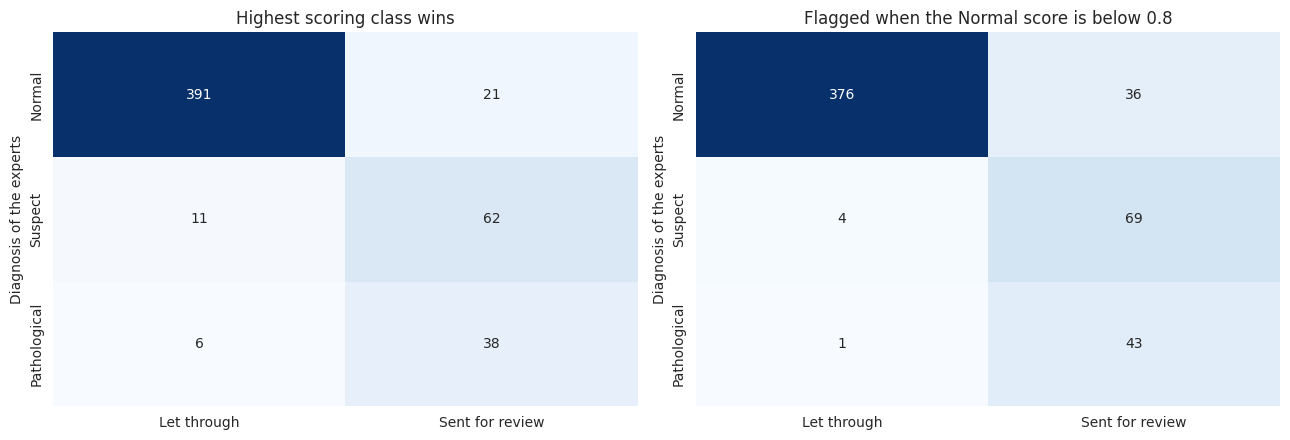

In [27]:
# What the rule chosen on the training folds does on the test set
normal_score_test = scores[:, list(model.classes_).index(1)]
flagged = normal_score_test < best_threshold

rows = []
for threshold in [0.5, 0.6, 0.7, best_threshold, 0.9]:
    mark = normal_score_test < threshold
    rows.append({
        'Threshold': threshold,
        'Pathological flagged': str(int(((y_test == 3) & mark).sum())) + ' of 44',
        'Suspect flagged': str(int(((y_test == 2) & mark).sum())) + ' of 73',
        'False alarms': str(int(((y_test == 1) & mark).sum())) + ' of 412',
        'Total sent for review': int(mark.sum()),
    })
print(pd.DataFrame(rows).set_index('Threshold'))

print("\nAt the threshold of", best_threshold, "chosen on the training folds:")
print("  pathological recordings caught:", int(((y_test == 3) & flagged).sum()), "of 44")
print("  pathological recordings missed:", int(((y_test == 3) & ~flagged).sum()))
print("  against", int(matrix[2, 0]), "missed by the plain three class model")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plain = np.array([[int(((y_test == c) & (predictions == 1)).sum()),
                   int(((y_test == c) & (predictions != 1)).sum())] for c in [1, 2, 3]])
ruled = np.array([[int(((y_test == c) & ~flagged).sum()),
                   int(((y_test == c) & flagged).sum())] for c in [1, 2, 3]])
for ax, m, title in zip(axes, [plain, ruled],
                        ['Highest scoring class wins',
                         'Flagged when the Normal score is below ' + str(best_threshold)]):
    sns.heatmap(m, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Let through', 'Sent for review'], yticklabels=names)
    ax.set_title(title)
    ax.set_ylabel('Diagnosis of the experts')
plt.tight_layout()
plt.show()

The rule chosen on the training folds catches **43 of the 44 pathological
recordings on the test set instead of 38**, so the recordings sent through as
healthy fall from 6 to 1. It also flags 69 of the 73 suspect recordings, against
62 before.

The price is on the top row: 36 normal recordings are sent for review instead of
21, so 8.7 percent of the healthy traces generate an unnecessary reading rather
than 5.1 percent. In a ward that means fifteen extra second looks per four
hundred healthy recordings, and five babies in distress who are no longer sent
home.

The threshold did not reach a perfect score on the test set even though it did on
the training folds, which is the expected behaviour and worth stating plainly: a
threshold chosen to just barely achieve something on one sample will fall a
little short on the next. If the missed case had to be eliminated as well the
threshold would have to be raised to 0.9, and the table shows what that costs,
68 false alarms instead of 36.

The two matrices side by side are the same model with two different decisions
read off it. Nothing was retrained between them. That is the point of an
evaluation built on scores rather than on labels: the model ranks the recordings
well, an AUC of 0.982 for the pathological class, and where to cut that ranking
is a clinical decision rather than a modelling one.

## Results (CRISP-DM 6: Deployment)

### Saving the model

What has to travel with this model is more than the fitted SVM. The scaler holds
the mean and the standard deviation of the 1584 training recordings, and a new
recording must be transformed with exactly those numbers before the kernel means
anything; the 21 columns have to arrive in the same order; and the threshold of
0.80 is part of the decision, not a note about it.

In [28]:
# What is saved: the fitted pipeline, the columns it expects in order, the
# meaning of the codes and the threshold the score is read against
bundle = {'model': model,
          'columns': list(X.columns),
          'class_names': HEALTH_NAMES,
          'review_threshold': best_threshold}

joblib.dump(bundle, 'model_fetal_svm.pkl', compress=3)
print("Size on disk:", round(os.path.getsize('model_fetal_svm.pkl') / 1024, 1), "KB")

# Load it back and check it gives the same answers
restored = joblib.load('model_fetal_svm.pkl')
print("The copy loaded from disk gives the same predictions:",
      bool((restored['model'].predict(X_test) == predictions).all()))

Size on disk: 30.5 KB
The copy loaded from disk gives the same predictions: True


In [29]:
# The saved model working recording by recording, four of each diagnosis
sample_index = y_test.groupby(y_test).head(4).index
sample = X_test.loc[sample_index]

sample_scores = restored['model'].predict_proba(sample)
normal_column = list(restored['model'].classes_).index(1)
report = pd.DataFrame({
    'prolong. decel.': sample['prolongued_decelerations'].values,
    'accelerations': sample['accelerations'].values,
    'abnormal STV': sample['abnormal_short_term_variability'].values,
    'Expert': [HEALTH_NAMES[c] for c in y_test.loc[sample_index]],
    'Model': [HEALTH_NAMES[c] for c in restored['model'].predict(sample)],
    'P(Normal)': sample_scores[:, normal_column].round(3),
})
report['Decision'] = np.where(
    report['P(Normal)'] < restored['review_threshold'], 'send for review', 'let through')
print(report.to_string(index=False))

 prolong. decel.  accelerations  abnormal STV       Expert        Model  P(Normal)        Decision
           0.000          0.003          59.0       Normal       Normal      0.838     let through
           0.000          0.001          29.0       Normal       Normal      0.986     let through
           0.000          0.000          22.0       Normal       Normal      0.976     let through
           0.000          0.000          65.0      Suspect      Suspect      0.002 send for review
           0.000          0.002          64.0       Normal       Normal      0.918     let through
           0.002          0.001          24.0 Pathological       Normal      0.711 send for review
           0.000          0.001          46.0      Suspect      Suspect      0.266 send for review
           0.002          0.000          66.0 Pathological Pathological      0.022 send for review
           0.002          0.000          64.0 Pathological Pathological      0.042 send for review
          

The table is the saved model working one recording at a time on twelve test
recordings, four of each diagnosis, with three of the 21 features printed next to
each answer, the probability it assigns to normal and the decision the threshold
produces.

The features track the answers. The four recordings the experts called normal all
receive a normal probability above 0.83, and three of the four
pathological ones sit at 0.02, 0.04 and 0.000, the last of those a trace with no
accelerations and an abnormal short term variability of 80. The four suspect
recordings all land between 0.002 and 0.27, so the model is not confusing them
with healthy traces even when it has to choose a label.

The sixth row is the one worth reading twice. It is a pathological recording, it
carries a prolonged deceleration, and its abnormal short term variability is 24,
which is a low value typical of a healthy trace. The model resolves that conflict
in favour of normal and **labels the recording Normal**. Its probability for
normal, however, is 0.711, well short of the confidence it gives to the genuinely
normal rows, and the threshold of 0.80 catches it: the decision column reads send
for review. This single row is the whole argument of the evaluation section in
one case. As a three way classifier the model got it wrong; as a filter it did
not.

Across the twelve, the labels are right eleven times and the review decision is
right twelve times: every abnormal recording is sent on and every normal one is
let through.

That is how the model should be used. It is not a replacement for the
obstetrician who reads the trace, it is a filter that decides which traces get
read first, and the number it should be trusted with is the probability, not the
label.

### Conclusions

A Support Vector Machine with a radial basis kernel was trained on 1584
cardiotocograph recordings and judged on 529 that took part in no decision, to
reproduce the three way classification, normal, suspect or pathological, that
three expert obstetricians agreed on.

The model was built entirely inside the training set. Three kernels were tuned on
their own grids and compared on five fold cross validation: the radial kernel
reached a macro F1 of 0.875, the polynomial 0.864 and the linear 0.800, so the
curved boundary is worth seven and a half points over the flat one, which is what
the exploration predicted when it found that the three classes do not lie along a
line in the variability features. C and gamma were then chosen together from a
grid of 25 pairs, landing at C = 100 and gamma = 0.1 on a flat region of the
surface.

The single most consequential decision was the scaling. Measured on the same
folds with the same C, the unscaled model reaches a macro F1 of 0.797 with a
gamma adapted to its raw units and 0.382 with the tuned gamma, against 0.876
scaled, and the preparation section explains why before the fact:
three histogram columns carry 64 percent of every raw distance while the six
event rate columns carry 0.00004 percent, and one of those six,
`prolongued_decelerations`, is the feature most correlated with the diagnosis in
the whole file. The class weighting, by contrast, was worth 0.3 points and is
reported as such.

On the test set the model reaches an accuracy of 0.911 and a macro F1 of 0.834
against a floor of 0.779, with per class F1 scores of 0.954 for normal, 0.744 for
suspect and 0.805 for pathological. It keeps 439 support vectors, and the fact
that it discards 80 percent of the normal recordings while keeping more than half
of the other two classes describes the geometry precisely: the suspect class is a
border region, not a category with an interior of its own.

The result that matters is not the accuracy. Read as a three way classifier the
model sends 6 of 44 pathological recordings through as normal, which for this
application is a failure. The ROC analysis shows the reason is the decision and
not the model, since the pathological class reaches an AUC of 0.982, so the
recordings are ranked almost correctly and only the cut is wrong. Replacing the
default rule with a threshold on the normal probability, chosen on the training
folds as the smallest value missing no pathological recording there, brings the
misses down from 6 to 1 out of 44 and raises the false alarm rate from 5.1 to 8.7
percent of the normal recordings. That trade is the reason the notebook was built
around macro F1 and per class recall rather than accuracy.

The limits should travel with the numbers. The 44 pathological recordings in the
test set mean every figure for that class moves by 2.3 points per recording, and
the threshold that missed nothing on the training folds still missed one case
here, which is what happens to a threshold chosen at the edge of its range. The
labels are three experts' consensus rather than the outcome of the pregnancy, so
the model reproduces a reading and not a fact, and it inherits whatever those
readers systematically got wrong. And the recordings come from one centre in
one period, so nothing here shows the model would transfer to another population
or another machine without being fitted again.

Used as intended the model is worth having. It is not a replacement for the
person who reads the trace; it is a filter that, on this test set, sends 148 of
529 recordings for a closer look and finds 43 of the 44 that needed one.